# Loading audio Data

In [1]:
!pip install -q miniminiai datasets torchaudio librosa

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.2/179.2 kB 4.0 MB/s eta 0:00:00


In [2]:
# Source: diffusers v0.11.1 mel.py — no JAX, no diffusers needed
import librosa
import numpy as np
from PIL import Image

class Mel:
    def __init__(self, x_res=256, y_res=256, sample_rate=22050, n_fft=2048,
                 hop_length=512, top_db=80, n_iter=32):
        self.x_res = x_res
        self.y_res = y_res
        self.sr = sample_rate
        self.n_fft = n_fft
        self.hop_length = hop_length
        self.top_db = top_db
        self.n_iter = n_iter
        self.audio = None

    def load_audio(self, audio_file=None, raw_audio=None):
        if audio_file is not None:
            self.audio, _ = librosa.load(audio_file, mono=True, sr=self.sr)
        else:
            self.audio = raw_audio

    def get_number_of_slices(self):
        return len(self.audio) // self.slice_size()

    def slice_size(self):
        return self.x_res * self.hop_length

    def audio_slice_to_image(self, slice):
        audio_slice = self.audio[slice * self.slice_size():(slice+1) * self.slice_size()]
        S = librosa.feature.melspectrogram(y=audio_slice, sr=self.sr,
                                           n_fft=self.n_fft, hop_length=self.hop_length,
                                           n_mels=self.y_res)
        log_S = librosa.power_to_db(S, ref=np.max, top_db=self.top_db)
        bytedata = (((log_S + self.top_db) * 255 / self.top_db)
                    .clip(0, 255).astype(np.uint8)[::-1])
        return Image.fromarray(bytedata)

    def image_to_audio(self, image):
        bytedata = np.frombuffer(image.tobytes(), dtype=np.uint8).reshape(
            (image.height, image.width))[::-1]
        log_S = bytedata.astype(np.float32) * self.top_db / 255 - self.top_db
        S = librosa.db_to_power(log_S)
        return librosa.feature.inverse.mel_to_audio(S, sr=self.sr, n_fft=self.n_fft,
                                                    hop_length=self.hop_length,
                                                    n_iter=self.n_iter)

In [3]:
import torch, random
import numpy as np
import torch.nn as nn
import fastcore.all as fc
import torch.nn.functional as F
from torch import optim
from miniminiai import *
from functools import partial
from datasets import load_dataset
from IPython.display import Audio
from torch.optim import lr_scheduler
from matplotlib import pyplot as plt
from torchaudio import transforms as AT
from torch.utils.data import default_collate
from torchvision.transforms import functional as TF

# Loading the Audio Data

In [4]:
# Settings for the Mel Spectrograms we'll use
sample_rate_mel = 16000
x_res = 128 # x resolution of spectrogram (time)
y_res = 128 # y resolution of spectrogram (frequency bins)
mel = Mel(x_res, y_res, sample_rate_mel)

In [5]:
# The dataset of bird calls
birdcall_dataset = load_dataset('tglcourse/5s_birdcall_samples_top20')

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:112: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md:   0%|          | 0.00/454 [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/977 [00:00<?, ?B/s]

data/train-00000-of-00006.parquet:   0%|          | 0.00/504M [00:00<?, ?B/s]

data/train-00001-of-00006.parquet:   0%|          | 0.00/505M [00:00<?, ?B/s]

data/train-00002-of-00006.parquet:   0%|          | 0.00/504M [00:00<?, ?B/s]

data/train-00003-of-00006.parquet:   0%|          | 0.00/505M [00:00<?, ?B/s]

data/train-00004-of-00006.parquet:   0%|          | 0.00/504M [00:00<?, ?B/s]

data/train-00005-of-00006.parquet:   0%|          | 0.00/504M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9595 [00:00<?, ? examples/s]

In [6]:
birdcall_dataset

DatasetDict({
    train: Dataset({
        features: ['audio', 'label'],
        num_rows: 9595
    })
})

In [7]:
birdcall_dataset['train'][0]

{'audio': <datasets.features._torchcodec.AudioDecoder at 0x7a533d5e9850>,
 'label': 'rewbla'}

In [8]:
# We need to re-sample the audio to match our target sample rate
sample_rate_dataset = 32000
resampler = AT.Resample(sample_rate_dataset, sample_rate_mel, dtype=torch.float32)

In [9]:
# Transform to turn an audio array into a PIL image
import random
def to_image(audio_array):
  audio_tensor = torch.tensor(audio_array).to(torch.float32)
  audio_tensor = resampler(audio_tensor)
  mel.load_audio(raw_audio=np.array(audio_tensor))
  num_slices = mel.get_number_of_slices()
  slice_idx = random.randint(0, num_slices-1) # Pic a random slice each time (excluding the last short slice)
  return mel.audio_slice_to_image(slice_idx)

In [10]:
class ImageDS:
  def __init__(self, ds):  self.ds = ds
  def __len__(self): return len(self.ds)
  def __getitem__(self, i):
    audio_array = self.ds[i]['audio']['array']
    im = to_image(audio_array)
    im = TF.to_tensor(im) - 0.5
    im = TF.resize(im, (x_res, y_res))
    return (im,)

In [11]:
tds = ImageDS(birdcall_dataset['train'].select(range(9000)))
vds = ImageDS((birdcall_dataset['train'].select(range(9000, 9500))))

In Hugging Face's datasets library, the `select()` method creates a `new dataset` `containing only the rows at the specific indices you provide`. ---

In [12]:
tds[0][0].shape,  # grey scale image

(torch.Size([1, 128, 128]),)

In [13]:
tds[0]  # second [0] is to unpack the tuple

(tensor([[[-0.3390, -0.3199, -0.3354,  ..., -0.3547, -0.3472, -0.3703],
          [-0.3270, -0.2879, -0.2720,  ..., -0.3161, -0.3157, -0.3428],
          [-0.2529, -0.2457, -0.2754,  ..., -0.3003, -0.3077, -0.3621],
          ...,
          [-0.1424, -0.0799, -0.0533,  ..., -0.0137, -0.0445, -0.1071],
          [-0.1935, -0.1419, -0.0774,  ..., -0.0670, -0.0762, -0.1346],
          [-0.2756, -0.1977, -0.1833,  ..., -0.2084, -0.1405, -0.1315]]]),)

/tmp/ipykernel_1129/1194146545.py:4: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  im = Image.fromarray(im.astype(np.uint8), mode='L')


(65024,)


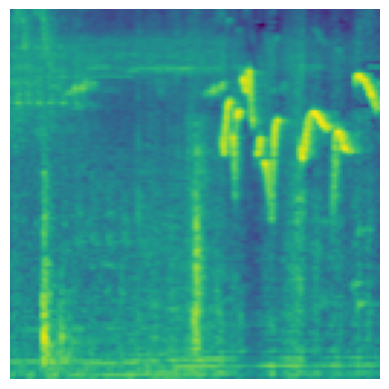

In [14]:
# view random sample
idx = random.randint(0,1000)
im = np.array((tds[idx][0][0]+0.5).clip(0,1)*225) #(64,64)
im = Image.fromarray(im.astype(np.uint8), mode='L')
a = mel.image_to_audio(im)
print(a.shape)
show_image(im)
display(Audio(a, rate=16000))

# DataLoaders

In [15]:
bs = 16
def collate_ddpm(b): return noisify(default_collate(b)[0])
dls = DataLoaders(*get_dls(tds, vds, bs, num_workers=4, collate_fn=collate_ddpm))

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


In [16]:
xb, yb = next(iter(dls.train))
xb[0].shape # [0] to unpack tuple

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


torch.Size([16, 1, 128, 128])

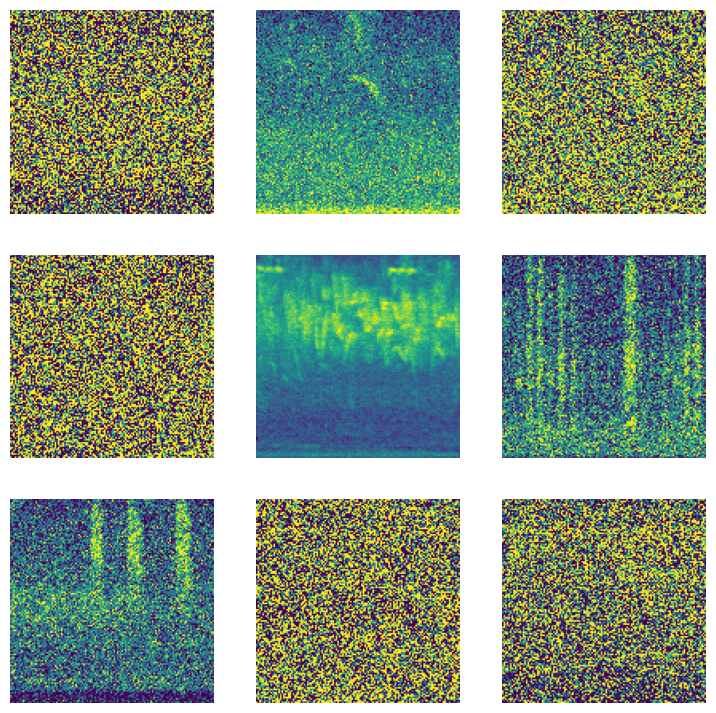

In [17]:
show_images(xb[0][:9].clip(-0.5, 0.5)+0.5)

# Model & Training

In [18]:
#@markdown The Conv Transformer Model from notebook-22
class LearnEmbSS(nn.Module):
    def __init__(self, sz, ni):
        super().__init__()
        self.scale = nn.Parameter(torch.zeros(sz, ni))
        self.shift = nn.Parameter(torch.zeros(sz, ni))

    def forward(self, x): return x*self.scale + self.shift

def mlp_(ni, nh):
    return nn.Sequential(nn.Linear(ni, nh), nn.GELU(), nn.LayerNorm(nh), nn.Linear(nh, ni))

class EmbTransformerBlk(nn.Module):
    def __init__(self, n_emb, ni, nh=None, attn_chans=8):
        super().__init__()
        if nh is None : nh=ni*4
        self.attn = SelfAttention(ni, attn_chans=attn_chans, transpose=False)
        self.mlp = mlp_(ni, nh)
        self.norm1 = nn.LayerNorm(ni)
        self.norm2 = nn.LayerNorm(ni)
        self.emb_proj = nn.Linear(n_emb, ni*2)

    def forward(self, x, t):
        emb = self.emb_proj(F.silu(t))[:, None]
        scale,shift = torch.chunk(emb, 2, dim=2)
        x = x + self.attn(self.norm1(x))
        x = x * (1+scale) + shift
        return x + self.mlp(self.norm2(x))

class SimpleDiffusion(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, nfs=(224,448,672,896), num_layers=1,
                 attn_chans=8, attn_start=1, n_mids=8):
        super().__init__()
        self.conv_in = nn.Conv2d(in_channels, nfs[0], kernel_size=3, padding=1)
        self.n_temb = nf = nfs[0]
        n_emb = nf*4
        self.emb_mlp = nn.Sequential(lin(self.n_temb, n_emb, norm=nn.BatchNorm1d),
                                     lin(n_emb, n_emb))
        self.downs = nn.ModuleList()
        n = len(nfs)
        for i in range(n):
            ni = nf
            nf = nfs[i]
            self.downs.append(DownBlock(n_emb, ni, nf, add_down=i!=n-1, num_layers=num_layers,
                                        attn_chans=0 if i<attn_start else attn_chans))

        self.le = LearnEmbSS(64, nf) # 64 is 8*8 final spacials at the end of down sampling
        self.mids = nn.ModuleList([EmbTransformerBlk(n_emb, nf) for _ in range(n_mids)])

        rev_nfs = list(reversed(nfs))
        nf = rev_nfs[0]
        self.ups = nn.ModuleList()
        for i in range(n):
            prev_nf = nf
            nf = rev_nfs[i]
            ni = rev_nfs[min(i+1, len(nfs)-1)]
            self.ups.append(UpBlock(n_emb, ni, prev_nf, nf, add_up=i!=n-1, num_layers=num_layers+1,
                                    attn_chans=0 if i>=n-attn_start else attn_chans))
        self.conv_out = pre_conv(nfs[0], out_channels, act=nn.SiLU, norm=nn.BatchNorm2d, bias=False)

    def forward(self, inp):
        x,t = inp
        temb = timestep_embedding(t, self.n_temb)
        emb = self.emb_mlp(temb)
        x = self.conv_in(x)
        saved = [x]
        for block in self.downs: x = block(x, emb)
        saved += [p for o in self.downs for p in o.saved]
        n,c,h,w = x.shape
        x = self.le(x.reshape(n,c,-1).transpose(1,2))
        for block in self.mids: x = block(x, emb)
        x = x.transpose(1,2).reshape(n,c,h,w)
        for block in self.ups: x = block(x, emb, saved)
        return self.conv_out(x)

def init_ddpm(model):
  for o in model.downs:
    for p in o.resnets: p.conv2[-1].weight.data.zero_()

  for o in model.ups:
    for p in o.resnets: p.conv2[-1].weight.data.zero_()

In [19]:
lr = 1e-4
epochs = 15
opt_func = partial(optim.AdamW, eps=1e-5, weight_decay=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), TrainCB()]
model = SimpleDiffusion(in_channels=1, out_channels=1, nfs=(16,32,256,384,512), num_layers=1, attn_chans=0, n_mids=6)
init_ddpm(model)
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

loss,epoch,train
0.772,0,train
0.479,0,eval
0.168,1,train
0.065,1,eval
0.057,2,train
0.061,2,eval
0.044,3,train
0.042,3,eval
0.038,4,train
0.045,4,eval


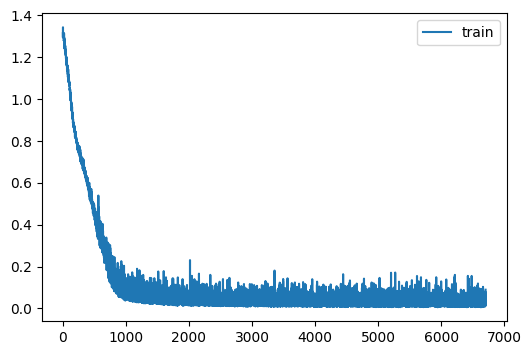

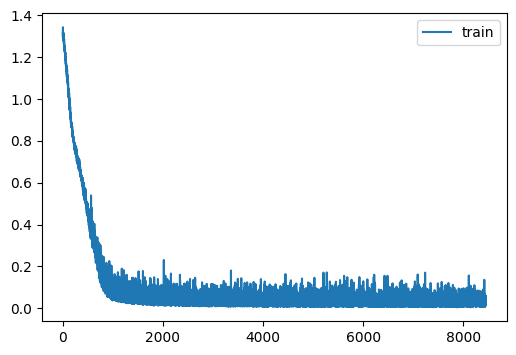

loss,epoch,train
0.772,0,train
0.479,0,eval
0.168,1,train
0.065,1,eval
0.057,2,train
0.061,2,eval
0.044,3,train
0.042,3,eval
0.038,4,train
0.045,4,eval


In [20]:
learn.fit(epochs)

# Sampling
Regular DDIM sampling, and then we turn the resulting images into audio using `mel.image_to_audio`

In [21]:
def ddim_step(x_t, noise, abar_t, abar_t1, bbar_t, bbar_t1, eta, sig, clamp=1.):
    sig = ((bbar_t1/bbar_t).sqrt() * (1-abar_t/abar_t1).sqrt()) * eta
    x_0_hat = (x_t-(1-abar_t).sqrt()*noise  )   / abar_t.sqrt()
    if clamp: x_0_hat = x_0_hat.clamp(-clamp,clamp)
    if bbar_t1<=sig**2+0.01: sig=0.  # set to zero if very small or NaN
    x_t = abar_t1.sqrt()*x_0_hat + (bbar_t1-sig**2).sqrt()*noise
    x_t += sig * torch.randn(x_t.shape).to(x_t)
    return x_0_hat,x_t

In [22]:
sz = (9,1,x_res,y_res)

In [23]:
preds = sample(ddim_step, model, sz, steps=100, eta=1., clamp=1.)

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:07&lt;00:00]</div>

In [24]:
s = (preds[-1]+0.5)

In [25]:
s.min(),s.max(),s.shape

(tensor(-0.1164), tensor(1.1700), torch.Size([9, 1, 128, 128]))

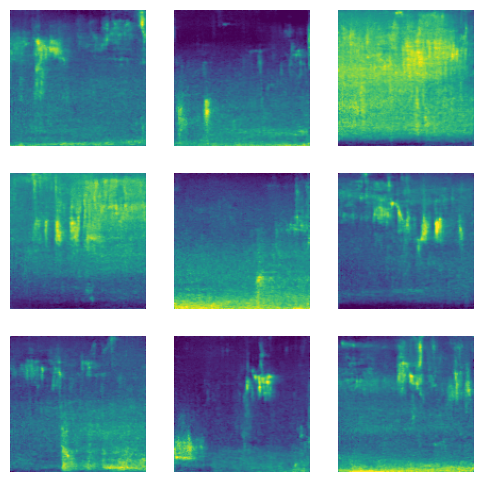

In [26]:
show_images(s[:9].clamp(0,1), imsize=2)

/tmp/ipykernel_1129/3645764446.py:3: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  im = Image.fromarray(im.astype(np.uint8), mode='L')


(65024,)


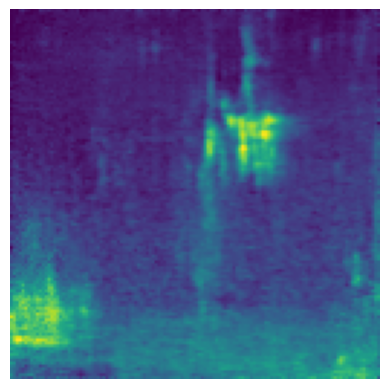

In [28]:
idx = 7
im = np.array((s[idx][0]).clip(0,1)*255)
im = Image.fromarray(im.astype(np.uint8), mode='L')
a = mel.image_to_audio(im)
print(a.shape)
show_image(im)
display(Audio(a, rate=16000))

/tmp/ipykernel_1129/3487398257.py:3: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  im = Image.fromarray(im.astype(np.uint8), mode='L')


(65024,)


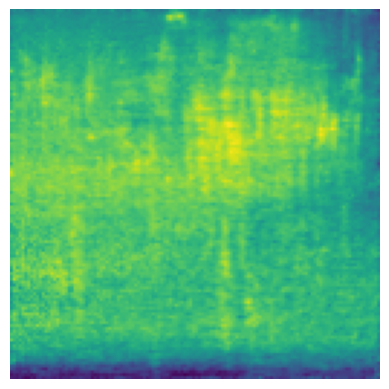

In [29]:
idx = 2
im = np.array((s[idx][0]).clip(0,1)*255)
im = Image.fromarray(im.astype(np.uint8), mode='L')
a = mel.image_to_audio(im)
print(a.shape)
show_image(im)
display(Audio(a, rate=16000))

/tmp/ipykernel_1129/4059009979.py:3: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  im = Image.fromarray(im.astype(np.uint8), mode='L')


(65024,)


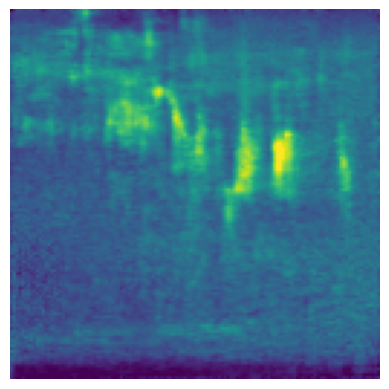

In [30]:
idx = 5
im = np.array((s[idx][0]).clip(0,1)*255)
im = Image.fromarray(im.astype(np.uint8), mode='L')
a = mel.image_to_audio(im)
print(a.shape)
show_image(im)
display(Audio(a, rate=16000))

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:03&lt;00:00]</div>

/tmp/ipykernel_1129/922724169.py:6: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  im = Image.fromarray(im.astype(np.uint8), mode='L')


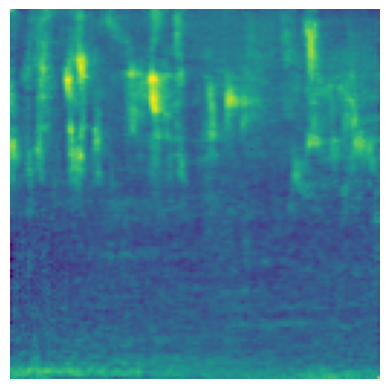

In [31]:
# Generate a single sample
sz = (1,1,x_res,y_res)
preds = sample(ddim_step, model, sz, steps=100, eta=1., clamp=1.)
s = (preds[-1]+0.5)
im = np.array((s[0][0]).clip(0, 1)*255)
im = Image.fromarray(im.astype(np.uint8), mode='L')
a = mel.image_to_audio(im)
show_image(im)
display(Audio(a, rate=16000))

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:02&lt;00:00]</div>

/tmp/ipykernel_1129/922724169.py:6: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  im = Image.fromarray(im.astype(np.uint8), mode='L')


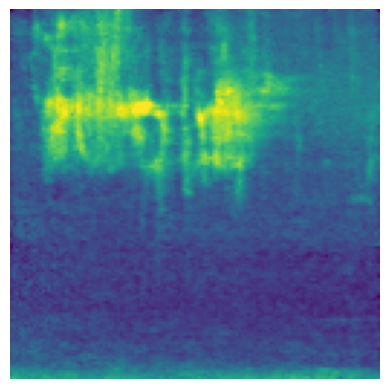

In [32]:
# Generate a single sample
sz = (1,1,x_res,y_res)
preds = sample(ddim_step, model, sz, steps=100, eta=1., clamp=1.)
s = (preds[-1]+0.5)
im = np.array((s[0][0]).clip(0, 1)*255)
im = Image.fromarray(im.astype(np.uint8), mode='L')
a = mel.image_to_audio(im)
show_image(im)
display(Audio(a, rate=16000))